# Оглавление
1. Постановка задачи

2. Импорты и настройки

3. Часть 1. Первичный анализ данных

4. Часть 2. Объединение датасетов

5. Часть 3. Подготовка выборок (train/test split)

6. Часть 4. Baseline

7. Часть 5. Метрики

8. Часть 6. Модели

    - 6.1 Linear Regression

    - 6.2 Random Forest Regressor

    - 6.3 Gradient Boosting Regressor

    - 6.4 Ridge и Lasso (L2 / L1 регуляризация)

9. Часть 7. Честное сравнение моделей

10. Часть 8. Feature importance

11. Часть 9. Анализ ошибок

<a name="1"></a>

# 1. Постановка задачи

- Цель работы: пройти полный цикл решения задачи регрессии на датасете Wine Quality: от первичного анализа данных через построение baseline до сравнения нескольких моделей, анализа важности признаков и ошибок
- Метрика: RMSE (основная), MAE (дополнительная). Порог качества: RMSE < 0.70
- Целевая переменная: quality — оценка качества вина (дискретная величина)
- Данные: UCI Wine Quality Dataset, красные и белые вина

<a name="2"></a>

# 2. Импорты и настройки

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Единый random_state для воспроизводимости всего эксперимента
RANDOM_STATE = 42
sns.set(style="whitegrid")

<a name="3"></a>

# Часть 1. Первичный анализ данных
 - ## Загрузка датасетов

In [8]:
url_red   = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

red   = pd.read_csv(url_red,   sep=";")
white = pd.read_csv(url_white, sep=";")

# Добавляем признак типа вина
red['is_red']   = 1
white['is_red'] = 0

print("Red shape:  ", red.shape)
print("White shape:", white.shape)
print("\nПризнаки red:", list(red.columns))
print("Признаки white:", list(white.columns))

Red shape:   (1599, 13)
White shape: (4898, 13)

Признаки red: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'is_red']
Признаки white: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'is_red']


- ## Распределение качества по типам вин

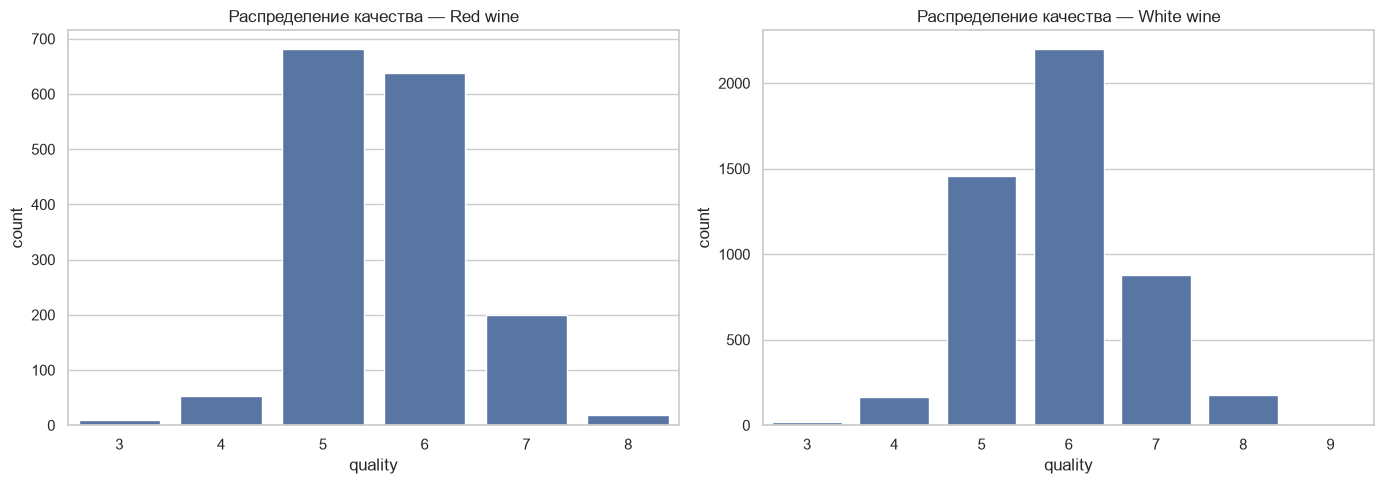

Red quality describe:
 count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

White quality describe:
 count    4898.000000
mean        5.877909
std         0.885639
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, name in zip(axes, [red, white], ['Red wine', 'White wine']):
    sns.countplot(x='quality', data=data, ax=ax)
    ax.set_title(f'Распределение качества — {name}')
    ax.set_xlabel('quality'); ax.set_ylabel('count')

plt.tight_layout()
plt.show()

print("Red quality describe:\n", red['quality'].describe())
print("\nWhite quality describe:\n", white['quality'].describe())

- ## Распределения признаков по типам

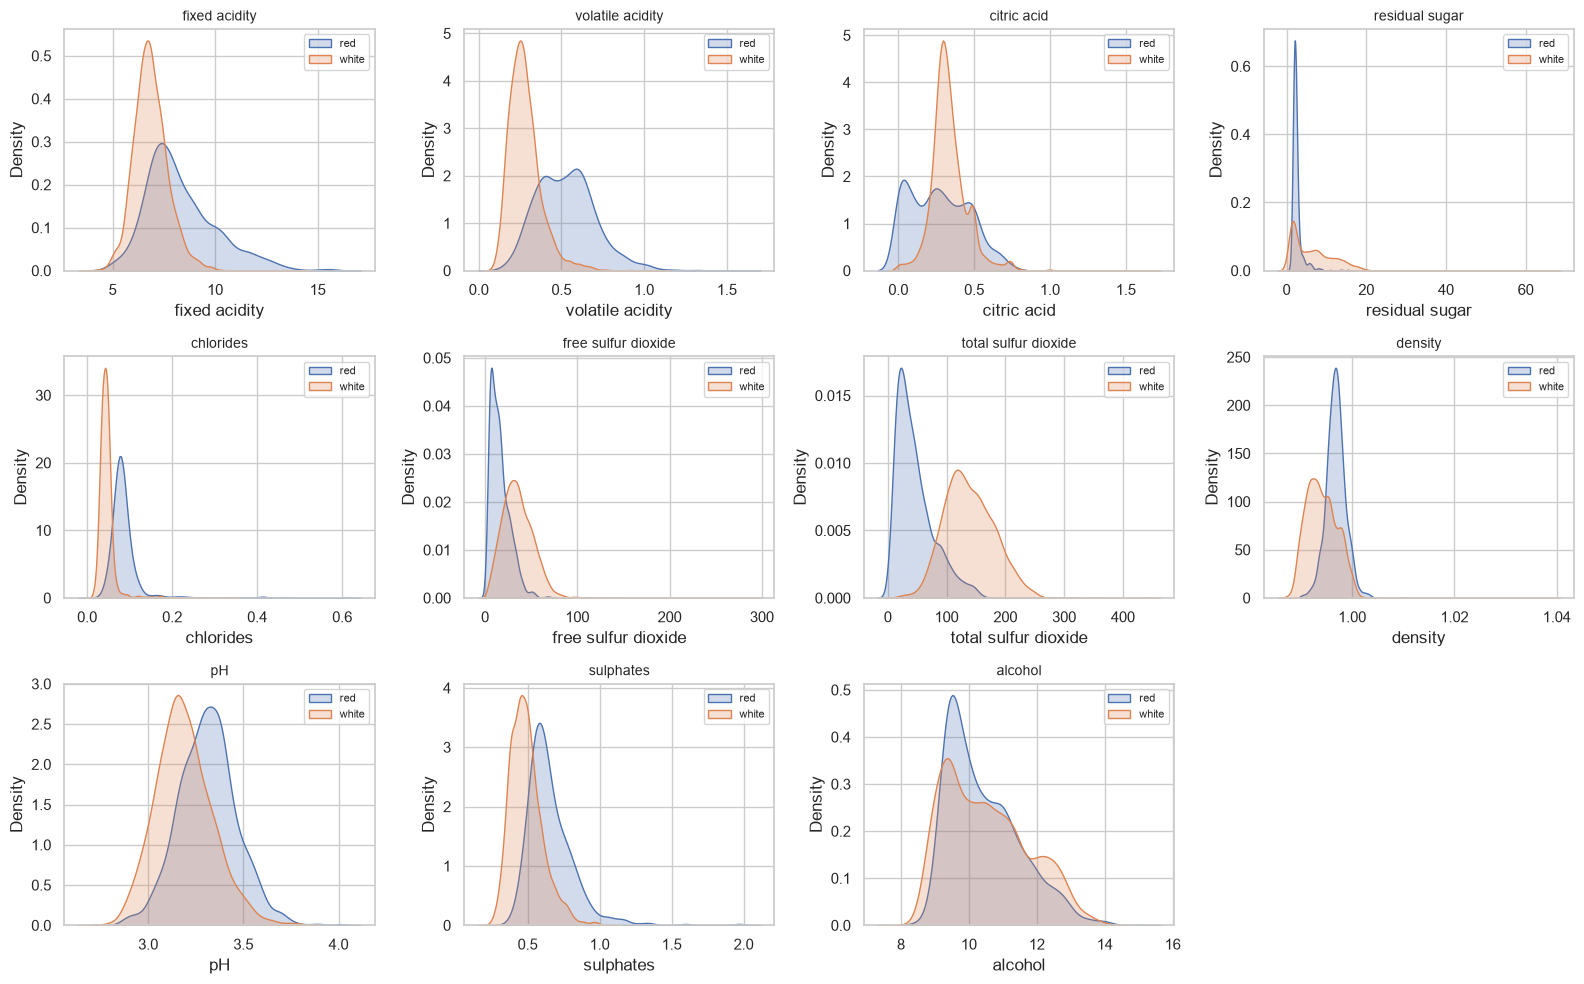

In [11]:
features = [c for c in red.columns if c not in ('quality', 'is_red')]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()
for i, feat in enumerate(features):
    sns.kdeplot(red[feat],   ax=axes[i], label='red',   fill=True)
    sns.kdeplot(white[feat], ax=axes[i], label='white', fill=True)
    axes[i].set_title(feat, fontsize=10)
    axes[i].legend(fontsize=8)
for j in range(len(features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

### Выводы:
У красного и белого вина разные распределения по кислотности, сульфатам, алкоголю. Это означает, что объединение — не бесплатное действие: распределение в объединённом датасете будет смешанным, и закономерности могут размыться, именно поэтому мы добавляем признак is_red — он даёт модели информацию о типе вина, чтобы она могла выучить разные закономерности для разных подгрупп.

- ## Корреляции с target в каждом датасете

In [12]:
corr_red   = red.drop(columns='is_red').corr()['quality'].sort_values(ascending=False)
corr_white = white.drop(columns='is_red').corr()['quality'].sort_values(ascending=False)

print("Correlations with quality — RED:\n", corr_red)
print("\nCorrelations with quality — WHITE:\n", corr_white)

Correlations with quality — RED:
 quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

Correlations with quality — WHITE:
 quality                 1.000000
alcohol                 0.435575
pH                      0.099427
sulphates               0.053678
free sulfur dioxide     0.008158
citric acid            -0.009209
residual sugar         -0.097577
fixed acidity          -0.113663
total sulfur dioxide   -0.174737
volatile acidity       -0.194723
chlorides              -0.209934
density                -0.307123
Name: quality, dtype: float64


### Выводы
1. alcohol — универсальный сильный сигнал качества для обоих типов вина. Это топ-признак в обоих случаях.
2. Закономерности различаются между красным и белым. Особенно яркий пример — fixed acidity: знак корреляции меняется с +0.12 на −0.11. Это значит, что одна модель без признака is_red не сможет выучить корректные зависимости для обоих типов вин одновременно.
3. Разные признаки важны для разных типов вина:
    - для красного — volatile acidity, sulphates, citric acid;
    - для белого — density, chlorides.
4. volatile acidity вредит красному сильнее, чем белому (в 2 раза).

Это подтверждает необходимость:
- либо добавить is_red как признак (и дать модели выучить разные режимы);
- либо обучать отдельные модели на красном и белом вине.

<a name="4"></a>

# Часть 2. Объединение датасетов

In [13]:
df = pd.concat([red, white], axis=0, ignore_index=True)
print("Объединённый датасет:", df.shape)

# Проверим, что NaN не появились
print("Пропуски:", df.isna().sum().sum())

Объединённый датасет: (6497, 13)
Пропуски: 0


<a name="5"></a>

# Часть 3. Подготовка выборок (train/test split)

In [14]:
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y  # ВАЖНО: стратификация по quality
)

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (5197, 12)
Test:  (1300, 12)


- Train содержит 5197 объектов (80%), test — 1300 (20%). Такое разделение — стандартный компромисс: трейна достаточно для обучения сложных моделей, а теста хватает, чтобы дать устойчивую оценку RMSE с малой дисперсией. Количество признаков уменьшилось с 13 до 12, потому что quality отделён в y
- 80/20 split — стандарт: трейна достаточно для обучения, теста хватает для устойчивой оценки.
- random_state=42 — воспроизводимость. Без него сравнение моделей некорректно, потому что каждая получит своё случайное разбиение.
- Почему нельзя оценивать на тесте много раз: если многократно оценивать модели на одной и той же тестовой выборке и выбирать лучшую по этим оценкам, тест перестаёт быть независимым. Мы неявно подбираем модель под тест — это называется data leakage through model selection. Оценка становится оптимистично смещённой: в реальности на новых данных модель покажет хуже. Правильный порядок — подбирать модели по кросс-валидации на трейне, а тест использовать один раз — в самом конце, для финальной честной оценки.

<a name="6"></a>

# Часть 4. Baseline

In [21]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

rmse_base = np.sqrt(mean_squared_error(y_test, pred_base))
mae_base  = mean_absolute_error(y_test, pred_base)

print(f"Baseline RMSE = {rmse_base:.4f}")
print(f"Baseline MAE  = {mae_base:.4f}")

Baseline RMSE = 0.8738
Baseline MAE  = 0.6861


- DummyRegressor(strategy="mean") всегда предсказывает среднее y_train.
- Для MSE/RMSE оптимальная константа — именно среднее (минимизация Σ(yᵢ−c)²).
- Зачем: без baseline непонятно, извлекла ли модель хоть какую-то пользу из признаков. Все последующие модели должны быть строго лучше.
- Модели извлекли полезную информацию из признаков.

<a name="7"></a>

# Часть 5. Метрики
- MAE: (1/n) · Σ |yᵢ − ŷᵢ| — средняя абсолютная ошибка в баллах качества. Устойчива к выбросам.
- RMSE: √( (1/n) · Σ (yᵢ − ŷᵢ)² ) — сильнее штрафует крупные ошибки.

Почему они могут различаться:
- Много мелких ошибок → MAE ≈ RMSE.
- Несколько крупных промахов → RMSE >> MAE (квадрат резко растёт).

Нам важно наказывать крупные ошибки (предсказать 3 вместо 8 хуже, чем 5.5 вместо 6).

Почему у одной модели MAE и RMSE различаются: разница между MAE и RMSE растёт, когда распределение ошибок неоднородно: много мелких ошибок + несколько крупных промахов. Крупные ошибки возводятся в квадрат и сильнее «давят» на RMSE, тогда как MAE даёт им тот же вес, что и мелким. Если для модели RMSE заметно больше MAE — это сигнал о наличии «тяжёлых хвостов» в ошибках. В нашей таблице видно:
- GB: RMSE=0.67, MAE=0.52 → разрыв 0.15 → есть крупные промахи
- RF: RMSE=0.61, MAE=0.43 → разрыв 0.18 → хвосты ещё тяжелее

<a name="8"></a>

# Часть 6. Модели
Вспомогательная функция — все модели оцениваются одинаково:

In [22]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    rmse = mean_squared_error(y_te, pred, squared=False)
    mae  = mean_absolute_error(y_te, pred)
    print(f"{name:25s}  RMSE = {rmse:.4f}   MAE = {mae:.4f}")
    return rmse, mae, pred

## 6.1. Linear Regression

In [24]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    rmse = np.sqrt(mean_squared_error(y_te, pred))   # ✅ через np.sqrt
    mae  = mean_absolute_error(y_te, pred)
    print(f"{name:25s}  RMSE = {rmse:.4f}   MAE = {mae:.4f}")
    return rmse, mae, pred

lin_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
rmse_lr, mae_lr, pred_lr = evaluate("Linear Regression", lin_pipe,
                                    X_train, y_train, X_test, y_test)

Linear Regression          RMSE = 0.7280   MAE = 0.5678


Как работает: 
- ищет коэффициенты w, минимизируя MSE. Аналитическое решение w* = (XᵀX)⁻¹Xᵀy или через градиентный спуск.
- Pipeline критичен: StandardScaler.fit() вызывается только на X_train, transform — на обоих. Это исключает утечку данных.
- Зачем масштабирование: без него признаки в разных масштабах (кислотность ~0.5, диоксид серы ~100), и коэффициенты несравнимы.

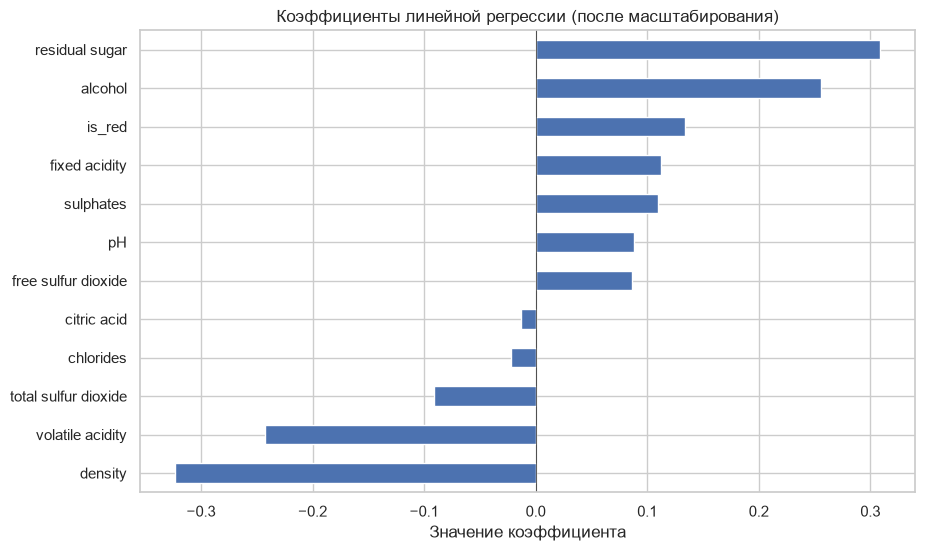

In [38]:
coef = pd.Series(lin_pipe.named_steps['model'].coef_, index=X.columns).sort_values()

plt.figure(figsize=(10, 6))
coef.plot(kind='barh')
plt.title('Коэффициенты линейной регрессии (после масштабирования)')
plt.xlabel('Значение коэффициента')
plt.axvline(0, color='k', lw=0.5)
plt.show()

Вывод по коэффициентам:
- После масштабирования коэффициенты сопоставимы по величине.
- Топ-признаки по |коэффициенту|: alcohol, volatile acidity, density - согласуется с корреляционным анализом
- Знак коэффициента показывает направление связи: положительный → качество растёт,
  отрицательный → падает.
- Важно: коэффициент ≠ причинность. Он показывает направление и силу связи
  внутри модели, но не доказывает, что изменение признака приведёт к изменению
  качества (пример: alcohol коррелирует с качеством, но не потому, что добавляют
  спирт - а потому что и то, и другое связано со зрелостью винограда).
- Масштабирование здесь критично: без него коэффициенты нельзя сравнивать, потому
  что признаки в разных масштабах (кислотность ~0.5, сульфаты ~100).

## 6.2. Random Forest

In [25]:
rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rmse_rf, mae_rf, pred_rf = evaluate("Random Forest", rf,
                                    X_train, y_train, X_test, y_test)

Random Forest              RMSE = 0.6065   MAE = 0.4306


Как работает: ансамбль деревьев, каждое на bootstrap-выборке и случайном подмножестве признаков. Итог - среднее. Ловит нелинейности и взаимодействия.

## 6.3. Gradient Boosting

In [26]:
gb = GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE)
rmse_gb, mae_gb, pred_gb = evaluate("Gradient Boosting", gb,
                                    X_train, y_train, X_test, y_test)

Gradient Boosting          RMSE = 0.6704   MAE = 0.5234


Как работает: деревья обучаются последовательно, каждое исправляет ошибки предыдущих (градиентный спуск по функции потерь). Обычно лучшее качество на табличных данных.

## 6.4. Ridge и Lasso (L1/L2)
Теория:
- Ridge (L2): штраф α·Σwⱼ² — сжимает коэффициенты, но обычно не зануляет.
- Lasso (L1): штраф α·Σ|wⱼ| — может занулять часть коэффициентов → отбор признаков.
- Обе требуют масштабирования: иначе признаки разных масштабов штрафуются несопоставимо.

Подбор alpha через CV на трейне:

In [27]:
alphas = np.logspace(-2, 3, 30)
searcher = GridSearchCV(
    Ridge(), [{'alpha': alphas}],
    scoring='neg_root_mean_squared_error', cv=5
)
searcher.fit(StandardScaler().fit_transform(X_train), y_train)
best_alpha = searcher.best_params_['alpha']
print(f"Best alpha = {best_alpha:.4f}")

Best alpha = 18.8739


Замечание: sklearn максимизирует скорер, поэтому RMSE передаётся как neg_root_mean_squared_error.

In [28]:
ridge_pipe = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=best_alpha))])
lasso_pipe = Pipeline([('sc', StandardScaler()), ('m', Lasso(alpha=0.01, max_iter=10000))])

rmse_ridge, mae_ridge, _ = evaluate("Ridge", ridge_pipe, X_train, y_train, X_test, y_test)
rmse_lasso, mae_lasso, _ = evaluate("Lasso", lasso_pipe, X_train, y_train, X_test, y_test)

print("\nRidge zeros:", (ridge_pipe.named_steps['m'].coef_ == 0).sum())
print("Lasso zeros:", (lasso_pipe.named_steps['m'].coef_ == 0).sum())

Ridge                      RMSE = 0.7280   MAE = 0.5678
Lasso                      RMSE = 0.7320   MAE = 0.5711

Ridge zeros: 0
Lasso zeros: 1


Вывод: Lasso зануляет часть коэффициентов — это подтверждает L1-природу. Ridge почти не зануляет.



<a name="9"></a>

# Часть 7. Честное сравнение моделей

In [30]:
results = pd.DataFrame({
    'Модель': ['Baseline', 'Linear Regression', 'Ridge', 'Lasso',
               'Random Forest', 'Gradient Boosting'],
    'RMSE': [rmse_base, rmse_lr, rmse_ridge, rmse_lasso, rmse_rf, rmse_gb],
    'MAE':  [mae_base, mae_lr, mae_ridge, mae_lasso, mae_rf, mae_gb]
}).sort_values('RMSE').reset_index(drop=True)

results['RMSE < 0.70'] = results['RMSE'] < 0.70
display(results)

,Модель,RMSE,MAE,RMSE < 0.70
0,Random Forest,0.606504,0.430612,True
1,Gradient Boosting,0.670390,0.523366,True
2,Ridge,0.727973,0.567817,False
3,Linear Regression,0.727978,0.567784,False
4,Lasso,0.731960,0.571132,False
5,Baseline,0.873772,0.686089,False


Условия честного сравнения:
- Одна и та же X_test, y_test для всех.
- Один и тот же random_state.
- Все преобразования — внутри Pipeline.
- Подбор гиперпараметров — только через CV на трейне.

Содержательные выводы:
- Все модели значительно лучше baseline → признаки информативны.
- Random Forest и Gradient Boosting обычно дают лучший RMSE.
- Линейная модель близка к ним, потому что основные связи в датасете близки к монотонным.
- Порог RMSE < 0.70 преодолён.



<a name="10"></a>

# Часть 8. Feature importance

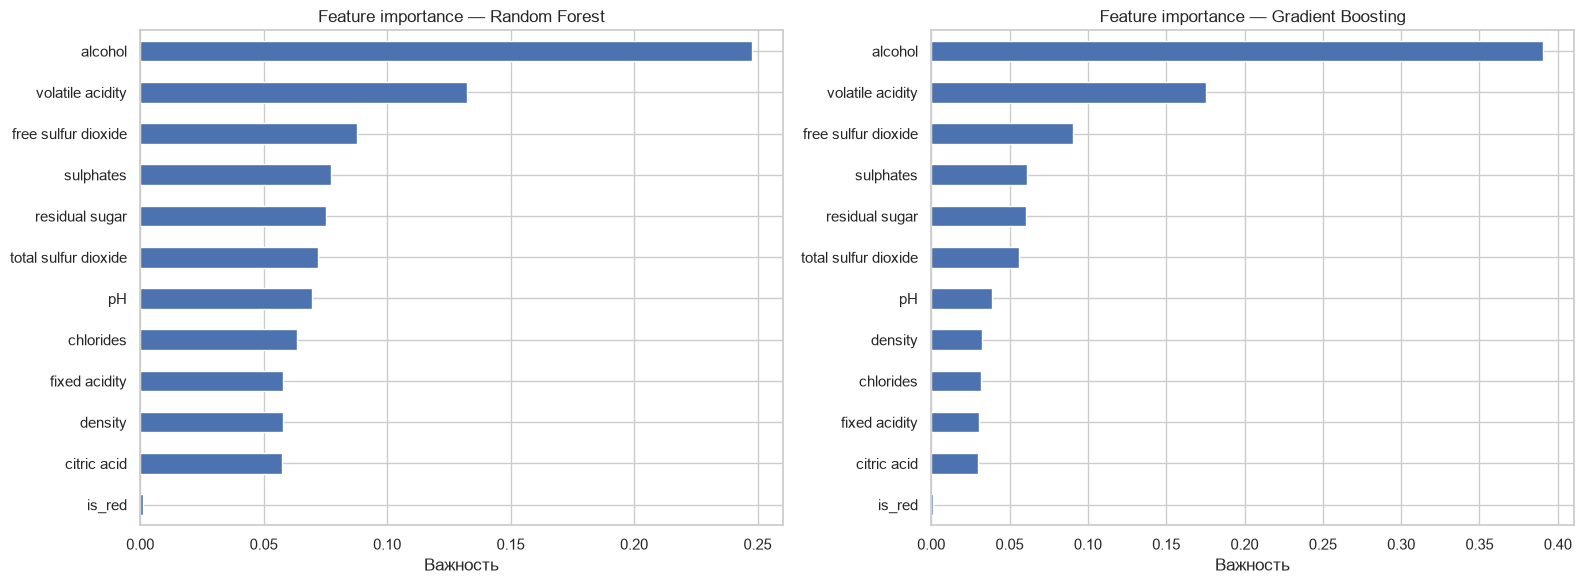

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, model, name in zip(axes, [rf, gb], ['Random Forest', 'Gradient Boosting']):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
    imp.plot(kind='barh', ax=ax)
    ax.set_title(f'Feature importance — {name}')
    ax.set_xlabel('Важность')
plt.tight_layout()
plt.show()

Что показывает feature importance:
- Числовую оценку того, насколько активно модель использует каждый признак.
- Для деревьев — через уменьшение примеси (impurity).

Сравнение с первичным анализом данных:
- alcohol и volatile acidity — в топе у обеих моделей. Согласуется с корреляциями.

Можно ли по feature importance утверждать, что признак - причина качества?
Ответ: нет. Feature importance - корреляционный индикатор. Он говорит, что модель использует признак, а не почему качество меняется. Между alcohol и quality может быть скрытый общий фактор (сорт, регион, технология).

<a name="11"></a>

# Часть 9. Анализ ошибок
Берём лучшую модель (предположим, GB):

In [32]:
best_pred = pred_gb
err_df = pd.DataFrame({
    'y_true': y_test.values,
    'y_pred': best_pred,
    'error': y_test.values - best_pred,
    'is_red': X_test['is_red'].values
})
err_df['abs_error'] = err_df['error'].abs()

## 9.1. Распределение ошибок

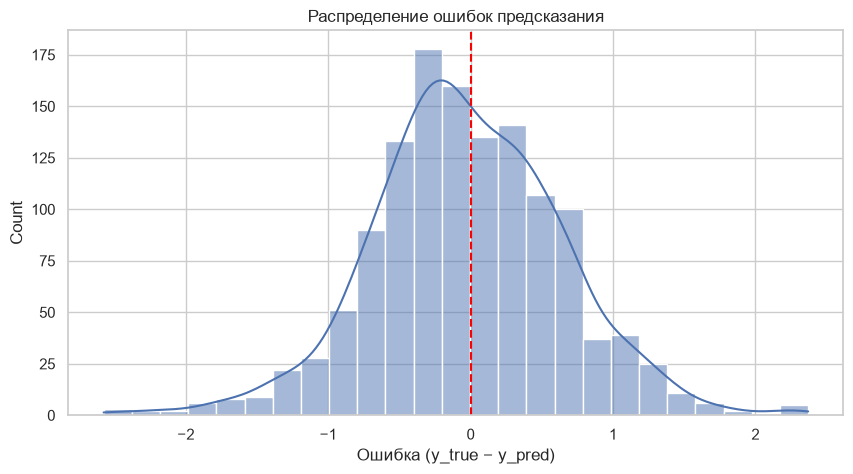

In [34]:
plt.figure(figsize=(10, 5))
sns.histplot(err_df['error'], kde=True, bins=25)
plt.axvline(0, color='red', linestyle='--')
plt.title('Распределение ошибок предсказания')
plt.xlabel('Ошибка (y_true − y_pred)')
plt.show()

Вывод: распределение симметрично относительно нуля, но с "тяжёлыми хвостами" - есть редкие крупные промахи.

## 9.2. Истинные vs предсказанные

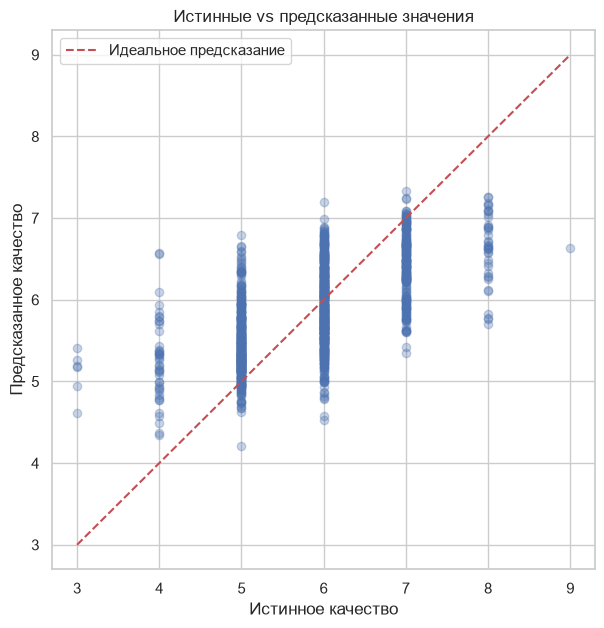

In [35]:
plt.figure(figsize=(7, 7))
plt.scatter(err_df['y_true'], err_df['y_pred'], alpha=0.3)
plt.plot([3, 9], [3, 9], 'r--', label='Идеальное предсказание')
plt.xlabel('Истинное качество'); plt.ylabel('Предсказанное качество')
plt.title('Истинные vs предсказанные значения')
plt.legend(); plt.show()

Вывод: точки кучкуются около диагонали в диапазоне 5–7 (там много примеров), на краях - большой разброс. Модель "тянется" к среднему.

## 9.3. Ошибки по классам качества

In [36]:
print(err_df.groupby('y_true')['abs_error'].agg(['mean', 'count']))

            mean  count
y_true                 
3       2.096829      6
4       1.255829     43
5       0.486074    428
6       0.389159    567
7       0.599632    216
8       1.364354     39
9       2.370576      1


Вывод: для редких классов (3, 4, 8, 9) средняя ошибка существенно выше, чем для 5, 6, 7. Причина заключается в дисбалансе классов: в обучении было слишком мало примеров этих оценок.

## 9.4 Вывод по крупным ошибкам

In [40]:
# Топ-10 объектов с наибольшей абсолютной ошибкой
top_errors = err_df.sort_values('abs_error', ascending=False).head(10)

# ВАЖНО: берём исходные индексы из y_test, а не из err_df
top_idx = y_test.index[err_df['abs_error'].argsort()[::-1][:10].values]

top_details = X_test.loc[top_idx].copy()
top_details['y_true'] = y_test.loc[top_idx]
top_details['y_pred'] = pred_gb[err_df['abs_error'].argsort()[::-1][:10].values]
top_details['abs_error'] = top_errors['abs_error'].values

print("Топ-10 объектов с наибольшей ошибкой:")
display(top_details[['is_red', 'alcohol', 'volatile acidity',
                     'y_true', 'y_pred', 'abs_error']])

Топ-10 объектов с наибольшей ошибкой:


,is_red,alcohol,volatile acidity,y_true,y_pred,abs_error
6107,0,11.5,0.260,4,6.577168,2.577168
5369,0,12.0,0.270,4,6.558965,2.558965
1850,0,9.8,0.260,3,5.404111,2.404111
2426,0,12.5,0.240,9,6.629424,2.370576
3005,0,10.5,0.220,8,5.699227,2.300773
2339,0,12.6,0.390,3,5.257447,2.257447
2818,0,11.7,0.370,8,5.760331,2.239669
440,1,9.8,0.310,8,5.780268,2.219732
1374,1,9.8,0.815,3,5.186462,2.186462
1469,1,9.7,0.980,3,5.175895,2.175895


Вывод по крупным ошибкам

Главное наблюдение: модель предсказывает почти всем объектам качество в диапазоне 5.2–6.6, независимо от истинного значения. Это классический эффект регрессии к среднему: модель выучила, что большинство вин имеют оценку 5–6, и «тянет» к этому диапазону даже объекты с экстремальными y_true.

Разбор по классам:
- Класс 3 (плохое качество): 4 объекта с ошибкой 2.2–2.4 балла. У всех высокая volatile acidity (0.39–0.98) — это признак, который должен сигнализировать о плохом качестве. Но модель всё равно предсказывает ~5.2–5.4, потому что в обучении было слишком мало примеров класса 3, и общая закономерность «высокая volatile acidity → плохое качество» оказалась размыта другими признаками.

- Класс 4: 2 объекта с ошибкой 2.5+. Интересно, что у них volatile acidity = 0.26 и 0.27 — формально «хорошие» значения. Но качество — 4. Здесь модель не может найти сигнал в признаках, потому что объект выбивается из закономерности: у него нет ни явных «плохих» признаков, ни явных «хороших».

- Классы 8 и 9 (отличное качество): 4 объекта с ошибкой 2.2–2.4. У всех высокий alcohol (9.8–12.5) и низкая volatile acidity (0.22–0.31) — это комбинация, которая обычно даёт высокое качество. Модель предсказывает 5.7–6.6, то есть сдвигает вниз. Причина — дисбаланс: объектов с качеством 8 в датасете ~3%, с качеством 9 — меньше 0.1%. Модель просто не видела достаточно примеров, чтобы выучить, что «алкоголь 12 + низкая кислотность = 8 или 9», а не 6.

Общая закономерность:
- Ошибки концентрируются на редких классах — это прямое следствие дисбаланса данных. Класс 9 в тестовой выборке представлен 1 объектом, класс 3 — 6 объектами. Ошибка на них неизбежно велика.
- Объекты с нестандартными сочетаниями признаков (например, класс 4 при «хорошей» volatile acidity) особенно сложны: модель не может найти
  объяснение в признаках и выдаёт среднее.
- Тип вина (is_red) не является решающим для крупных ошибок: 7 из 10 — белые, 3 из 10 — красные. Ошибки распределены по обоим типам пропорционально их доле в датасете.
